# 02 · Model Development: candidates, comparison, selection

8 candidate PD models are trained on the **training set only**, all on the output of the single preprocessor `pd_model.features.preprocessing` (imputation of every feature, one-hot `region_risk`, scaling; §0 below). **This notebook is read-only:** the training itself is done once, by `scripts/train.py` (`pd_model.models`), which is the only writer of `models/` and `reports/training/`. Here we load those results and present the development evidence: the data, why these drivers, the candidate comparison and the selected model. They are compared with 5-fold stratified cross-validation, and one is selected. The test set is not touched here; it is reserved for the independent validation in notebook 03.

| Candidate | Why it's in the set |
|---|---|
| **A. Logistic regression, all features** | Transparent baseline with every available variable |
| **B. Logistic regression, parsimonious** | Only statistically significant, economically sensible drivers; the simplest defensible model |
| **C. WoE scorecard** (WoE-binned features + logistic regression) | Industry/regulatory standard for retail PD: monotone, interpretable, converts to score points |
| **D. LightGBM, monotone-constrained** | Captures non-linearity and interactions while keeping every driver's direction economically sensible |
| **E. LightGBM, unconstrained** | Upper bound on the discrimination available; shows what the constraints cost |
| **F. XGBoost, monotone-constrained** | Second gradient-boosting implementation (level-wise trees, different regularisation), to make sure the result doesn't depend on one library |
| **G. XGBoost, unconstrained** | As E, for XGBoost |
| **H. Random forest** | Bagging instead of boosting: a different way to capture non-linearity, to make sure the conclusion doesn't depend on the boosting family |

In [1]:
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from pd_model.config import load_config
from pd_model.data.loading import load_split
from pd_model.features.preprocessing import MISSING_PREFIX, learned_parameters, select_outputs
from pd_model.models.scorecard import Scorecard
from pd_model.models.training import load_artifacts, load_training_report, model_input_columns

pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")

cfg = load_config()
TARGET = cfg.target
train, _ = load_split(cfg.paths.processed_dir)      # the test set is not touched here
preprocessor, model, meta = load_artifacts(cfg)      # written by scripts/train.py, sha256-verified
bundle = joblib.load(cfg.paths.candidates)           # all fitted candidates
report = load_training_report(cfg.paths.training_dir)
X, y = train[cfg.raw_features], train[TARGET]
Xp = preprocessor.transform(X)
print(X.shape, "->", Xp.shape, f"| default rate {y.mean():.4f}")
print("artifacts:", {k: v[:12] + "…" for k, v in meta["sha256"].items()})

(14000, 14) -> (14000, 20) | default rate 0.1573
artifacts: {'preprocessor': '6ba568d2de6f…', 'model': '2be8829f1049…'}


## 0. Data and preprocessor
**Cleaning** (`scripts/clean_data.py` → `pd_model.data.cleaning`) applies the EDA actions that fix *this file*:
- drops the leaky `recovery_flag_after_90d`
- resets the duplicated index (`row_id`, `block`)
- divides the 80 inflated loans by 10
- rebuilds the 700 deleted incomes as `loan / dti`
- flags inconsistent records (validation only)
- makes a stratified 70/30 split

**The preprocessor** is fitted on train and saved for validation and the service:

```
raw record ─► FeatureBuilder ─► Winsorizer ─► ColumnTransformer
              domain rules      dti cap        numeric:     median imputer (+ missing flags) ─► StandardScaler
                                               categorical: most-frequent imputer ─► OneHotEncoder(drop="first")
```
- **`FeatureBuilder`:** age 99 → missing; income capped at 30k; `dti = loan / income` if absent; `income_capped`, `total_past_due`, `any_past_due`.
- **Imputers:** every column has one, so a future record missing **any** field is still scored.
- **`region_risk`:** one-hot encoded, region 0 as reference (unequal risk steps, EDA §9.1).

In [2]:
cleaning = json.loads(cfg.paths.cleaning_report.read_text())
params = learned_parameters(preprocessor)
print(json.dumps(cleaning, indent=2))
print("winsor caps:", params["winsor_caps"], "| region categories:", params["categories"])
pd.DataFrame({"median (imputation)": params["numeric_impute_median"],
              "scaler mean": params["scaler_mean"], "scaler sd": params["scaler_scale"]})

{
  "rows": 20000,
  "dropped_leaky": [
    "recovery_flag_after_90d"
  ],
  "loans_divided_by_10": 80,
  "incomes_reconstructed": 700,
  "inconsistent_records": 2281,
  "max_identity_error": 2.336816962156263e-09,
  "train_rows": 14000,
  "test_rows": 6000,
  "train_default_rate": 0.15728571428571428,
  "test_default_rate": 0.15733333333333333
}
winsor caps: {'dti': 2.788457396817476} | region categories: {'region_risk': ['0', '1', '2']}


,median (imputation),scaler mean,scaler sd
client_history_in_bank,30.0000,29.9151,17.0280
age,38.1453,38.5626,11.1534
income,"30,000.0000","26,570.2448","5,679.0725"
employment_years,5.9868,6.1116,3.7531
loan_amount,"9,921.8327","12,651.2769","9,814.7314"
interest_rate,0.1201,0.1197,0.0297
num_loans,3.0000,3.0067,1.7441
credit_utilization,0.3220,0.3395,0.1793
past_due_30,0.0000,0.4018,0.6314
past_due_60,0.0000,0.2016,0.4493


## 1. Feature selection for the parsimonious logistic regression (candidate B)
We fit a logistic regression on all preprocessed value features. Engineered features are excluded because they are exact or near-exact combinations of base features, and missing flags are excluded because they are almost constant. A variable is kept only if it passes all 3 tests:
1. **Statistically significant**: p < 0.01.
2. **Economically sensible sign**: risk rises with delinquency, DTI, utilisation and regional risk.
3. **Material**: it improves CV Gini.

Features are standardised, so each coefficient is the change in log-odds per standard deviation (per dummy for `region_risk`).

In [3]:
base_cols = [c for c in Xp.columns
             if not c.startswith(MISSING_PREFIX) and c not in ("income_capped", "total_past_due", "any_past_due")]
full = sm.Logit(y.values, sm.add_constant(Xp[base_cols])).fit(disp=0)
coef_tbl = full.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]]
coef_tbl["significant (p<0.01)"] = coef_tbl["P>|z|"] < 0.01
coef_tbl.sort_values("P>|z|")

,Coef.,Std.Err.,P>|z|,significant (p<0.01)
const,-2.0547,0.0353,0.0000,True
past_default,0.4650,0.0195,0.0000,True
past_due_60,0.3068,0.0213,0.0000,True
past_due_90,0.2438,0.0196,0.0000,True
past_due_30,0.2438,0.0225,0.0000,True
region_risk_2,0.5942,0.0767,0.0000,True
region_risk_1,0.3592,0.0547,0.0000,True
dti,0.3677,0.0707,0.0000,True
credit_utilization,0.1188,0.0245,0.0000,True
client_history_in_bank,0.0770,0.0247,0.0018,True


- 7 source variables are clearly significant (p ≈ 0): `past_default`, `past_due_30/60/90`, `dti`, `region_risk` (both dummies) and `credit_utilization`. All of them have the expected positive sign.
- `client_history_in_bank` is significant (p ≈ 0.002), but its sign is **counter-intuitive**: longer relationships with the bank would mean *higher* risk. It has zero IV (see EDA) and its effect is tiny, so it is **excluded on economic grounds**. A model must be explainable to credit committee.
- `income`, `loan_amount`, `interest_rate`, `age`, `employment_years` and `num_loans` add nothing once `dti` is in the model. Since `dti` = loan / income exactly (EDA §7.1), it already carries the income and loan information.

The selected source features are recorded in `configs/config.yaml` (`training.parsimonious`). `region_risk` expands to its 2 dummies.

In [4]:
PARS = select_outputs(list(Xp.columns), cfg.training["parsimonious"], cfg.categorical)
print("candidate B inputs:", PARS)
vif = pd.Series([variance_inflation_factor(sm.add_constant(Xp[PARS]).values, i + 1) for i in range(len(PARS))],
                index=PARS, name="VIF")
vif.to_frame()

candidate B inputs: ['credit_utilization', 'past_due_30', 'past_due_60', 'past_due_90', 'past_default', 'dti', 'region_risk_1', 'region_risk_2']


,VIF
credit_utilization,1.0008
past_due_30,1.0008
past_due_60,1.0009
past_due_90,1.0005
past_default,1.0009
dti,1.0005
region_risk_1,1.0511
region_risk_2,1.0503


VIF ≈ 1.00–1.05 for every input, so there is **no multicollinearity**, and the coefficients can be read one at a time.

## 2. Candidates, tuning and cross-validated comparison
Every table reports **Gini and AUC** side by side (Gini = 2·AUC − 1, so they rank models identically). Selection uses Gini, the credit-risk convention: "within 0.01 Gini of the best" is the same as "within 0.005 AUC".
`scripts/train.py` → `run_training` (in `pd_model.models.training`):
- builds the 8 candidates (`pd_model.models.candidates`) on the preprocessed column names;
- tunes the boosting models on a small grid;
- scores every candidate with 5-fold stratified CV.

Inside each fold the **whole `preprocessor + model` pipeline is refitted**, so medians, caps and scaling never see the validation fold.

- **Monotone constraints** for the boosting models follow the EDA and credit logic: +1 means risk can only rise with the feature, −1 means it can only fall, and 0 means unconstrained. Both `region_risk` dummies get +1 (every region is riskier than the reference region 0), and missing flags are unconstrained.
- **The WoE scorecard** leaves out the engineered features, because redundant engineered features caused coefficient sign flips in an earlier iteration.
- **The boosting grid** is small and strongly regularised (shallow trees, large minimum leaf size). Signal in this data is weak, so deep trees overfit.

In [5]:
for name, tbl in report["tuning"].items():
    print(name, "best:", meta["best_params"][name])
    display(tbl.head(3))

D_lgbm_monotone best: {'min_child_samples': 300, 'n_estimators': 200, 'num_leaves': 4}


,min_child_samples,n_estimators,num_leaves,cv_gini,cv_auc,cv_gini_std,train_gini,train_auc
0,300,200,4,0.4354,0.7177,0.0219,0.4614,0.7307
1,100,200,4,0.4352,0.7176,0.0216,0.4629,0.7314
2,300,400,4,0.4349,0.7174,0.0252,0.4809,0.7404


E_lgbm_free best: {'min_child_samples': 100, 'n_estimators': 200, 'num_leaves': 4}


,min_child_samples,n_estimators,num_leaves,cv_gini,cv_auc,cv_gini_std,train_gini,train_auc
0,100,200,4,0.4347,0.7174,0.0202,0.4673,0.7336
1,300,200,4,0.4347,0.7173,0.0210,0.4648,0.7324
2,300,400,4,0.4325,0.7163,0.0240,0.4875,0.7438


F_xgb_monotone best: {'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 400}


,max_depth,min_child_weight,n_estimators,cv_gini,cv_auc,cv_gini_std,train_gini,train_auc
0,2,5,400,0.4351,0.7175,0.0218,0.4831,0.7415
1,2,20,400,0.4351,0.7175,0.0232,0.4799,0.7399
2,2,5,200,0.4330,0.7165,0.0187,0.4623,0.7312


G_xgb_free best: {'max_depth': 2, 'min_child_weight': 20, 'n_estimators': 400}


,max_depth,min_child_weight,n_estimators,cv_gini,cv_auc,cv_gini_std,train_gini,train_auc
0,2,20,400,0.4335,0.7168,0.0227,0.4839,0.7420
1,2,5,400,0.4330,0.7165,0.0211,0.4885,0.7442
2,2,5,200,0.4329,0.7165,0.0185,0.4657,0.7328


H_random_forest best: {'max_depth': 8, 'min_samples_leaf': 100}


,max_depth,min_samples_leaf,cv_gini,cv_auc,cv_gini_std,train_gini,train_auc
0,8.0000,100,0.4222,0.7111,0.0144,0.4899,0.7449
1,8.0000,25,0.4220,0.7110,0.0162,0.5414,0.7707
2,NaN,100,0.4201,0.7101,0.0141,0.5106,0.7553


The shallowest trees win in every case (4 leaves for LightGBM, depth 2 for XGBoost), and the random forest prefers large leaves (≥ 100 clients) with limited depth. Larger trees widen the train/CV gap without improving CV Gini, which is a sign that **there is little non-linear structure to exploit**.

In [6]:
models = bundle["models"]
comp = report["comparison"].copy()
comp["n inputs"] = [len(model_input_columns(models[n])) if n != "C_woe_scorecard"
                    else len(models[n].named_steps["woe"].feature_names_in_) for n in comp.index]
comp

,CV Gini,CV AUC,CV Gini std,CV AUC std,CV KS,CV Brier,Train Gini,Train AUC,Overfit gap (Gini),Overfit gap (AUC),n inputs
A_logreg_all,0.4414,0.7207,0.0277,0.0138,0.3382,0.1176,0.4476,0.7238,0.0062,0.0031,20
B_logreg_parsimonious,0.4406,0.7203,0.0314,0.0157,0.3362,0.1176,0.4420,0.7210,0.0014,0.0007,8
D_lgbm_monotone,0.4354,0.7177,0.0219,0.0109,0.3321,0.1188,0.4614,0.7307,0.0261,0.0130,20
F_xgb_monotone,0.4351,0.7175,0.0218,0.0109,0.3307,0.1178,0.4831,0.7415,0.0480,0.0240,20
E_lgbm_free,0.4347,0.7174,0.0202,0.0101,0.3300,0.1186,0.4673,0.7336,0.0326,0.0163,20
G_xgb_free,0.4335,0.7168,0.0227,0.0113,0.3332,0.1183,0.4839,0.7420,0.0504,0.0252,20
H_random_forest,0.4222,0.7111,0.0144,0.0072,0.3268,0.1213,0.4899,0.7449,0.0677,0.0339,20
C_woe_scorecard,0.4162,0.7081,0.0220,0.0110,0.3247,0.1202,0.4230,0.7115,0.0069,0.0034,8


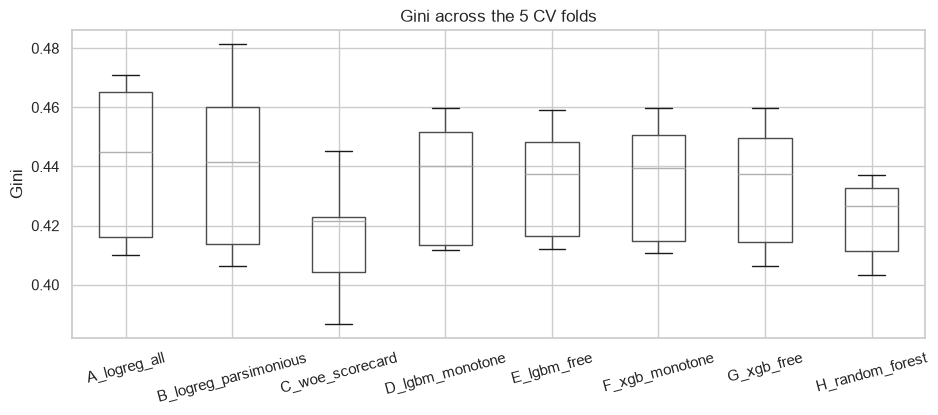

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
report["cv_folds"]["Gini"].unstack("candidate").boxplot(ax=ax)
ax.set_title("Gini across the 5 CV folds"); ax.set_ylabel("Gini")
plt.xticks(rotation=15); plt.show()

### Are the differences significant?
A paired comparison on identical folds, against the parsimonious model B.

In [8]:
report["paired"]

,mean Δ Gini vs ref,mean Δ AUC vs ref,folds better than ref,paired t p-value
A_logreg_all,0.0008,0.0004,3.0000,0.8287
C_woe_scorecard,-0.0244,-0.0122,0.0000,0.0102
D_lgbm_monotone,-0.0052,-0.0026,1.0000,0.3413
E_lgbm_free,-0.0058,-0.0029,1.0000,0.3422
F_xgb_monotone,-0.0055,-0.0027,1.0000,0.3277
G_xgb_free,-0.0070,-0.0035,1.0000,0.2193
H_random_forest,-0.0184,-0.0092,1.0000,0.0911


### Selection
**Criteria, in priority order** (typical for a bank PD model under model-risk governance):
1. **Discrimination** (CV Gini). Models within **0.01 Gini** of the best are treated as practically equivalent, since that is well inside the fold-to-fold spread (std ≈ 0.02–0.03).
2. **Simplicity / interpretability**: among equivalent models, choose the simplest. It is easier to explain to credit committee, auditors and the regulator, it gives clear reason codes for declined applicants, and it is cheaper to implement and monitor.
3. **Stability**: a small train–CV gap.
4. **Calibration**: checked on the test set in notebook 03.

In [9]:
print("best CV Gini:", round(comp["CV Gini"].max(), 4))
print("practically equivalent (within 0.01):",
      comp.index[comp["CV Gini"] >= comp["CV Gini"].max() - cfg.training["equivalence_gini"]].tolist())
print("SELECTED  :", bundle["selected"])
print("CHALLENGER:", bundle["challenger"])
assert bundle["selected"] == meta["selected"]

best CV Gini: 0.4414
practically equivalent (within 0.01): ['A_logreg_all', 'B_logreg_parsimonious', 'D_lgbm_monotone', 'F_xgb_monotone', 'E_lgbm_free', 'G_xgb_free']
SELECTED  : B_logreg_parsimonious
CHALLENGER: D_lgbm_monotone


## 3. Saved artifacts
Written by `scripts/train.py`, not by this notebook:
- `preprocessor.joblib` is fitted on the full training set.
- `model.joblib` is the selected model, which takes the preprocessor's output.
- `candidates.joblib` holds all fitted candidates for benchmarking in notebook 03.
- `metadata.json` records feature names, learned parameters, the CV table, library versions and sha256 hashes.
- `reports/training/` holds the CV evidence shown above (comparison, paired tests, per-fold scores, tuning grids).

In [10]:
print(json.dumps({k: meta[k] for k in ("selected", "model_features", "model_source_features", "sha256", "versions")}, indent=2))

{
  "selected": "B_logreg_parsimonious",
  "model_features": [
    "credit_utilization",
    "past_due_30",
    "past_due_60",
    "past_due_90",
    "past_default",
    "dti",
    "region_risk_1",
    "region_risk_2"
  ],
  "model_source_features": [
    "credit_utilization",
    "dti",
    "past_default",
    "past_due_30",
    "past_due_60",
    "past_due_90",
    "region_risk"
  ],
  "sha256": {
    "preprocessor": "6ba568d2de6f25c81c244ffa267ecf55265e34c11045faebabf4172386f5f0a9",
    "model": "2be8829f1049b1d2c7bd19c60a34d785ae6af7d4c8cabcb3d8b7211d97f21e42"
  },
  "versions": {
    "pd-model": "1.1.0",
    "scikit-learn": "1.9.1",
    "pandas": "3.1.1",
    "numpy": "2.5.4",
    "joblib": "1.6.0"
  }
}


## 4. The selected model
Coefficients are per standard deviation (and per dummy for `region_risk`). The last 2 columns convert them back to **1 raw unit** of each feature, using the scaler's standard deviation, for reading by credit committee.

In [11]:
cols = model_input_columns(model)
sel = sm.Logit(y.values, sm.add_constant(Xp[cols])).fit(disp=0)
out = sel.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|", "[0.025", "0.975]"]].copy()
out["Odds ratio (per SD / dummy)"] = np.exp(out["Coef."])
scale = pd.Series(meta["preprocessor_params"]["scaler_scale"])
raw_coef = out["Coef."].drop("const") / scale.reindex(cols).fillna(1.0)   # dummies are not scaled
out["Coef. per raw unit"] = raw_coef
out["Odds ratio per raw unit"] = np.exp(raw_coef)
print(f"Pseudo R² (McFadden): {sel.prsquared:.4f}   AIC: {sel.aic:,.1f}")
out

Pseudo R² (McFadden): 0.1095   AIC: 10,867.6


,Coef.,Std.Err.,P>|z|,[0.025,0.975],Odds ratio (per SD / dummy),Coef. per raw unit,Odds ratio per raw unit
const,-2.0500,0.0353,0.0000,-2.1191,-1.9809,0.1287,NaN,NaN
credit_utilization,0.1178,0.0245,0.0000,0.0698,0.1657,1.1250,0.6568,1.9285
past_due_30,0.2445,0.0225,0.0000,0.2005,0.2885,1.2770,0.3872,1.4729
past_due_60,0.3071,0.0213,0.0000,0.2653,0.3489,1.3595,0.6836,1.9811
past_due_90,0.2431,0.0196,0.0000,0.2046,0.2815,1.2752,1.1207,3.0671
past_default,0.4655,0.0194,0.0000,0.4274,0.5036,1.5928,1.5290,4.6136
dti,0.3961,0.0208,0.0000,0.3554,0.4368,1.4861,0.9163,2.5000
region_risk_1,0.3571,0.0547,0.0000,0.2500,0.4642,1.4292,0.3571,1.4292
region_risk_2,0.5913,0.0766,0.0000,0.4412,0.7415,1.8064,0.5913,1.8064


**Reading the coefficients (odds ratios per raw unit):**
- A past default multiplies the odds of default by about **4.6**.
- Each additional delinquency multiplies the odds by about **1.5** for 30+ DPD, **2.0** for 60+ and **3.1** for 90+. The severity ordering 30 < 60 < 90 is exactly what credit logic predicts.
- Each +1.0 of DTI multiplies the odds by about **2.5**.
- Utilisation going from 0% to 100% multiplies the odds by about **1.9**.
- **Region:** compared with region 0, region 1 multiplies the odds by **1.43** and region 2 by **1.81**. The steps are unequal (+0.36 then +0.23 log-odds). The previous single numeric term forced equal steps (odds ratio 1.37 per step), which understated region 1 and overstated region 2. One-hot encoding removes that assumption at the cost of one extra parameter.

Every effect is significant, correctly signed and independent of the others (VIF ≈ 1). The `dti` coefficient is estimated on the winsorised value (cap at the train p99.5).

In [12]:
lr_sel = model.named_steps["lr"]
print("sklearn vs statsmodels coefficients (should match):")
pd.DataFrame({"sklearn": np.r_[lr_sel.intercept_, lr_sel.coef_[0]], "statsmodels": sel.params}, index=["const"] + cols)

sklearn vs statsmodels coefficients (should match):


,sklearn,statsmodels
const,-2.0501,-2.0500
credit_utilization,0.1178,0.1178
past_due_30,0.2445,0.2445
past_due_60,0.3072,0.3071
past_due_90,0.2429,0.2431
past_default,0.4654,0.4655
dti,0.3962,0.3961
region_risk_1,0.3572,0.3571
region_risk_2,0.5911,0.5913


### Score scaling
For business use, PD converts to a score: **600 points at odds 50:1 (good:bad), 20 points to double the odds (PDO)**. Higher score = lower risk.

score = offset − factor × logit(PD), where factor = PDO / ln 2. Each variable therefore contributes −factor × coef points per unit; the table uses the per-raw-unit coefficients.

In [13]:
sc = Scorecard(**{k: cfg.scorecard[k] for k in ("pdo", "base_score", "base_odds")})
pts = pd.DataFrame({"coef per raw unit": raw_coef, "points per raw unit": raw_coef.map(sc.points_per_unit)})
pts

,coef per raw unit,points per raw unit
credit_utilization,0.6568,-18.9503
past_due_30,0.3872,-11.1726
past_due_60,0.6836,-19.7259
past_due_90,1.1207,-32.3373
past_default,1.5290,-44.1180
dti,0.9163,-26.4387
region_risk_1,0.3571,-10.3041
region_risk_2,0.5913,-17.0615


For example, each 90+ DPD loan costs about 32 points, a past default about 44 points, and living in region 2 about 17 points (region 1: 10).

## 5. Challenger: what does LightGBM see?

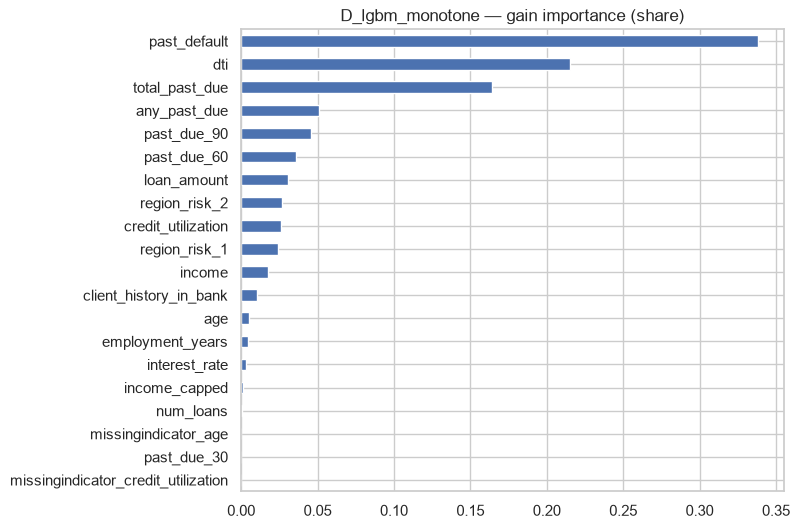

In [14]:
m = models["D_lgbm_monotone"]
imp = pd.Series(m.booster_.feature_importance("gain"), index=m.feature_name_).sort_values()
(imp / imp.sum()).plot.barh(figsize=(7, 6), title="D_lgbm_monotone — gain importance (share)")
plt.show()

The challenger relies on the same drivers (past default, DPD, DTI, region, utilisation). It finds no additional signal in the other variables, which independently confirms the parsimonious specification.

## Summary
- All 8 candidates land in a narrow band, **CV Gini 0.42–0.44**: the information in the data is limited.
- Neither gradient boosting (LightGBM or XGBoost, constrained or not), nor a random forest, nor WoE binning beats the parsimonious logistic regression. The relationships are essentially **linear in the logit and additive**. The WoE scorecard is now further behind (0.416). It is binned on the imputed values, so it no longer gets the separate "missing age" bin it had before, and it is the only candidate that is statistically worse than B (p = 0.01).
- **The random forest (H)** reaches CV Gini 0.422 (AUC 0.711), 0.018 below B. That is outside the 0.01 equivalence margin, though not significant fold by fold (p = 0.09). It also overfits the most of any candidate (train–CV gap 0.068). Bagging, like boosting, finds no extra signal, so the conclusion doesn't depend on the family of tree models.
- **Selected: B, the parsimonious logistic regression.** It has 7 source drivers (8 inputs, with region one-hot encoded), ties for the best discrimination (CV Gini 0.441 / AUC 0.720), has the smallest overfit gap (0.001), and its drivers are significant, correctly signed and independent.
- **Challenger: D, monotone LightGBM.** It is retained for benchmarking in validation and future monitoring.
- Saved by `scripts/train.py`: `models/preprocessor.joblib` and `models/model.joblib` (scoring = `model.predict_proba(preprocessor.transform(raw))`), plus `candidates.joblib`, `oof_predictions.parquet` and `metadata.json`.